# Defensive Shape Quality & Integrity — feasibility study

**Idea.** A defensive shape is *good* when, at every moment, the best thing the attack can do is
not very valuable — and when whatever the attack actually does, the shape does not get worse from
state $n$ to state $n+1$.

This notebook tests whether that idea can be measured with the SkillCorner open data
(tracking + dynamic events + physical aggregates + body pose), on **one match:
Brisbane Roar 0–1 Perth Glory (match 1925299)**. It is picked because it is the only match
that has *all four* data types in this repository (the body-pose sample is from this game).

## How the idea is formalised

| Your idea | What this notebook computes |
|---|---|
| "all potential plays at state $n$" | Every 1 m × 1 m cell of the pitch is treated as a possible pass target |
| "potential EPV gain from the offense's perspective" | $G(c) = P_{succ}(c)\,V(c) - (1-P_{succ}(c))\,V_{opp}(c) - V(\text{ball})$ |
| "considering each defender's physical capabilities" | $P_{succ}$ comes from a **physics-based pitch-control model**: each player's top speed (`psv99`) and acceleration (`timetosprint_top3`) set how fast they reach every cell |
| "body position is optimal" | Facing direction (from body-pose shoulders, or movement direction as a proxy) adds a **turn-time penalty** to reaching cells behind the player, and is scored on its own |
| "proximity to nearest attacker is optimal given physical traits" | A defender marks well if they can **reach their nearest attacker before a pass could arrive**, and are goal-side |
| "tiles that connect the defending individuals" | **Delaunay triangulation** of the defending outfield players. Each triangle is a *tile*, each edge a *link*. A tile is strong if defenders own the space inside it; a link is broken if a ball can be played through it |
| "was the action the best one from the defending perspective" | **Action percentile**: where the real action's gain ranks among all possible gains (0 = attack picked the least dangerous option, 1 = attack picked the best) |
| "did not deteriorate the shape from $n$ to $n+1$" | $\Delta I = I_{n+1} - I_n$, the change in the shape integrity index |
| "soccer is a chain reaction" | The same evaluation is repeated at $n+1$, $n+2$, … along a real sequence, so you can see one action open (or close) the next |

**Everything here is a first-pass prototype.** Parameter values (reaction time, ball speed, weights)
are reasonable defaults from the pitch-control literature, not fitted. Section 9 checks whether the
model agrees with SkillCorner's own EPV and pass-completion numbers, which is the real feasibility test.

In [1]:
import json
import gzip
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection, LineCollection
from matplotlib.colors import TwoSlopeNorm
from mplsoccer import Pitch
from scipy.ndimage import gaussian_filter
from scipy.spatial import Delaunay
from scipy.stats import spearmanr

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.dpi"] = 110

# Find the repo root (the folder that contains data/matches) from wherever the notebook runs
ROOT = Path.cwd()
while not (ROOT / "data" / "matches").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
DATA = ROOT / "data"
MATCH_ID = 1925299
MDIR = DATA / "matches" / str(MATCH_ID)
print("repo root:", ROOT)

repo root: /home/claude/soccer_data


## 1. Load the match

> **Tracking file note.** `*_tracking_extrapolated.jsonl` is stored with Git LFS. If the file below is
> ~130 bytes, it is only a pointer: run `git lfs install && git lfs pull --include="data/matches/1925299/*"`
> in the repo, or download it from
> `https://media.githubusercontent.com/media/misoverfitting/soccer_data/master/data/matches/1925299/1925299_tracking_extrapolated.jsonl`.

In [2]:
tracking_path = MDIR / f"{MATCH_ID}_tracking_extrapolated.jsonl"
assert tracking_path.stat().st_size > 10_000, "Tracking file is a Git LFS pointer — see note above."

match = json.load(open(MDIR / f"{MATCH_ID}_match.json"))
events = pd.read_csv(MDIR / f"{MATCH_ID}_dynamic_events.csv", low_memory=False)

HALF_L, HALF_W = match["pitch_length"] / 2, match["pitch_width"] / 2
home_id, away_id = match["home_team"]["id"], match["away_team"]["id"]
team_name = {home_id: match["home_team"]["short_name"], away_id: match["away_team"]["short_name"]}

players = pd.DataFrame([{
    "player_id": p["id"], "name": p["short_name"], "team_id": p["team_id"],
    "role": p["player_role"]["name"], "position_group": p["player_role"]["position_group"],
} for p in match["players"]])
pid_team = players.set_index("player_id")["team_id"].to_dict()
pid_name = players.set_index("player_id")["name"].to_dict()
goalkeepers = set(players.loc[players.role == "Goalkeeper", "player_id"])

# Load raw tracking lines once; parse frames on demand (line index == frame number)
with open(tracking_path) as f:
    TRACK_LINES = f.readlines()
assert json.loads(TRACK_LINES[1000])["frame"] == 1000

print(f"{team_name[home_id]} {match['home_team_score']}–{match['away_team_score']} {team_name[away_id]}")
print(f"{len(TRACK_LINES):,} tracking frames @10 fps, {len(events):,} dynamic events")

Brisbane FC 0–1 Perth Glory
61,301 tracking frames @10 fps, 5,222 dynamic events


### Coordinate convention
Event coordinates in SkillCorner's dynamic events are already oriented so the **team in possession
attacks towards +x**. Tracking is in fixed pitch coordinates, so we rotate it 180° whenever the
attacking team plays `right_to_left`. From here on, **the attack always goes left → right and the
defending team protects the goal at x = +52.5.**

In [3]:
def frame_state(frame, attacking_team_id, attacking_side):
    """Positions + velocities of all players and the ball at `frame`, in the attacking frame of reference."""
    flip = -1.0 if attacking_side == "right_to_left" else 1.0
    rows = []
    for fr in (frame - 2, frame, frame + 2):           # +/- 0.2 s for a smoothed velocity
        r = json.loads(TRACK_LINES[fr])
        rows.append({p["player_id"]: (p["x"] * flip, p["y"] * flip, p["is_detected"]) for p in r["player_data"]})
        if fr == frame:
            b = r["ball_data"]
            ball = np.array([b["x"] * flip, b["y"] * flip]) if b["x"] is not None else None
    prev, cur, nxt = rows
    out = []
    for pid, (x, y, det) in cur.items():
        if pid not in pid_team:
            continue
        a = prev.get(pid, (x, y, det)); c = nxt.get(pid, (x, y, det))
        vx, vy = (c[0] - a[0]) / 0.4, (c[1] - a[1]) / 0.4
        out.append({"player_id": pid, "x": x, "y": y, "vx": vx, "vy": vy, "detected": det,
                    "attacking": pid_team[pid] == attacking_team_id, "gk": pid in goalkeepers})
    st = pd.DataFrame(out)
    st["name"] = st.player_id.map(pid_name)
    return st, ball

# quick sanity check: the event says D. Williams shoots from (45.8, 6.9) at frame 44303
shot = events[(events.event_type == "player_possession") & (events.frame_start == 44303)].iloc[0]
st, ball = frame_state(44303, shot.team_id, shot.attacking_side)
print(st.loc[st.name == "D. Williams", ["x", "y"]].round(1).to_dict("records"), "ball:", ball.round(1))

[{'x': 45.7, 'y': 6.8}] ball: [47.9  6.2]


## 2. A value surface $V(x, y)$ — "how much is the ball worth here?"

SkillCorner attaches an EPV value to the start of every player possession (`possession_epv_for_start`).
Pooling those over all 20 matches in the repo and smoothing them gives a data-driven map of how valuable
it is to have the ball at each location. Losing the ball at $(x, y)$ hands the opponent the ball at
$(-x, -y)$ in *their* frame, so $V_{opp}(x, y) = V(-x, -y)$.

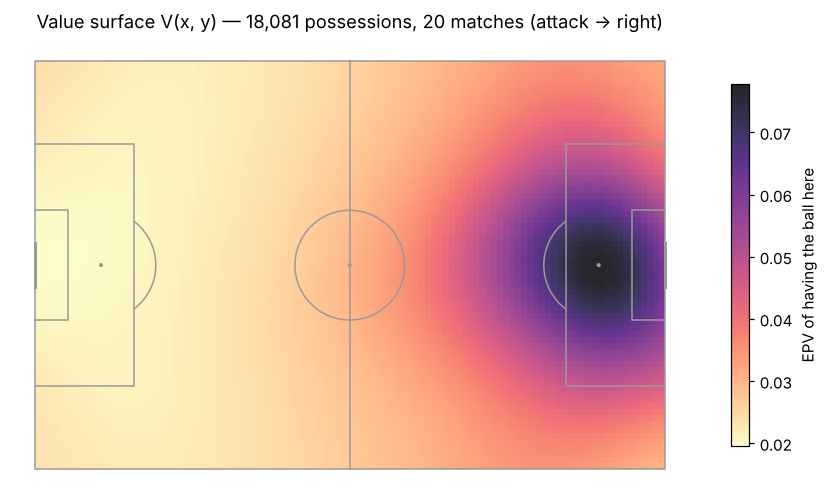

In [4]:
GRID_X = np.arange(-HALF_L + 0.5, HALF_L, 1.0)
GRID_Y = np.arange(-HALF_W + 0.5, HALF_W, 1.0)
GX, GY = np.meshgrid(GRID_X, GRID_Y)                     # shape (68, 105)
CELLS = np.column_stack([GX.ravel(), GY.ravel()])        # (7140, 2)

def build_value_surface(bin_m=3.0, smooth=2.5):
    frames = []
    for f in sorted((DATA / "matches").glob("*/*_dynamic_events.csv")):
        e = pd.read_csv(f, usecols=["event_type", "x_start", "y_start", "possession_epv_for_start"], low_memory=False)
        frames.append(e[e.event_type == "player_possession"].dropna())
    e = pd.concat(frames)
    xb = np.arange(-HALF_L, HALF_L + bin_m, bin_m); yb = np.arange(-HALF_W, HALF_W + bin_m, bin_m)
    s, _, _ = np.histogram2d(e.x_start, e.y_start, [xb, yb], weights=e.possession_epv_for_start)
    n, _, _ = np.histogram2d(e.x_start, e.y_start, [xb, yb])
    prior = e.possession_epv_for_start.median()
    k = 5.0                                              # shrink sparse bins toward the median
    m = (s + k * prior) / (n + k)
    m = gaussian_filter(m, smooth, mode="nearest")
    from scipy.interpolate import RegularGridInterpolator
    xc = (xb[:-1] + xb[1:]) / 2; yc = (yb[:-1] + yb[1:]) / 2
    f = RegularGridInterpolator((xc, yc), m, bounds_error=False, fill_value=None)
    return f(np.column_stack([GX.ravel(), GY.ravel()])).reshape(GX.shape), len(e)   # (68, 105)

V, n_obs = build_value_surface()
V_flat = V.ravel()
V_opp_flat = V[::-1, ::-1].ravel()                       # value to the opponent if the ball is lost here

def value_at(xy):
    ix = np.clip(np.round(xy[..., 0] + HALF_L - 0.5).astype(int), 0, len(GRID_X) - 1)
    iy = np.clip(np.round(xy[..., 1] + HALF_W - 0.5).astype(int), 0, len(GRID_Y) - 1)
    return V[iy, ix]

pitch = Pitch(pitch_type="skillcorner", pitch_length=2 * HALF_L, pitch_width=2 * HALF_W,
              line_color="#9a9a9a", pitch_color="white", linewidth=1)
fig, ax = pitch.draw(figsize=(8, 5))
im = ax.imshow(V, extent=[-HALF_L, HALF_L, -HALF_W, HALF_W], origin="lower", cmap="magma_r", alpha=0.85, zorder=0)
fig.colorbar(im, ax=ax, shrink=0.7, label="EPV of having the ball here")
ax.set_title(f"Value surface V(x, y) — {n_obs:,} possessions, 20 matches (attack → right)")
plt.show()

## 3. Each player's physical capabilities

From the season physical aggregates:
* **Top speed** $v_{max}$ = `psv99` (km/h → m/s).
* **Acceleration** $a_{max} \approx$ sprint threshold (25 km/h) / `timetosprint_top3`, clipped to 3–7 m/s².

Players missing from the aggregates (too few 60+ min games) get their position-group median.

In [5]:
phys = pd.read_csv(DATA / "aggregates" / "aus1league_physicalaggregates_20242025.csv")
phys = phys.groupby("player_id")[["psv99", "timetosprint_top3"]].mean()

players = players.join(phys, on="player_id")
for col in ["psv99", "timetosprint_top3"]:
    players[col] = players[col].fillna(players.groupby("position_group")[col].transform("median")).fillna(phys[col].median())
players["vmax"] = players.psv99 / 3.6
players["amax"] = np.clip((25 / 3.6) / players.timetosprint_top3, 3.0, 7.0)
PHYS = players.set_index("player_id")[["vmax", "amax"]]
players[["name", "team_id", "position_group", "psv99", "timetosprint_top3", "vmax", "amax"]] \
    .assign(team=lambda d: d.team_id.map(team_name)).drop(columns="team_id") \
    .sort_values("vmax", ascending=False).round(2).head(12)

,name,position_group,psv99,timetosprint_top3,vmax,amax,team
27,A. Faisal,Wide Attacker,31.10,1.47,8.64,4.72,Perth Glory
34,A. Burke-Gilroy,Full Back,30.58,1.27,8.49,5.47,Brisbane FC
1,N. Acosta,Wide Attacker,30.10,1.47,8.36,4.72,Brisbane FC
26,R. Warland,Full Back,29.68,1.48,8.24,4.69,Perth Glory
25,A. Lebib,Central Defender,29.64,1.32,8.23,5.26,Perth Glory
18,H. Bility,Central Defender,29.02,1.22,8.06,5.69,Brisbane FC
6,K. Jelacic,Wide Attacker,28.90,1.47,8.03,4.72,Brisbane FC
7,J. Hingert,Full Back,28.54,1.71,7.93,4.06,Brisbane FC
4,T. Ostler,Wide Attacker,28.48,1.44,7.91,4.82,Perth Glory
23,J. Risdon,Full Back,28.45,1.37,7.90,5.07,Perth Glory


## 4. Physics-aware pitch control

For each player $i$ and each cell $c$, the time to get there:

1. **React**: keep moving with current velocity for $t_{react}$ = 0.5 s.
2. **Turn**: if the cell is behind the way the player faces, add $\theta / \omega$ ($\omega$ = 360°/s, so a full about-turn costs 0.5 s).
3. **Run**: accelerate at $a_{max,i}$ up to $v_{max,i}$.

The ball travels at 15 m/s. Whoever (effectively) arrives first controls the cell:

$$P_{att}(c) = \sigma\big(k\,[\,\tilde t_{def}(c) - \tilde t_{att}(c)\,]\big), \quad \tilde t = \max(t_{player}, t_{ball}) + 0.3\,t_{player},\; k = \tfrac{\pi}{\sqrt{3}\,0.45}$$

(The $0.3\,t_{player}$ term is a tie-break: if both players are already there when the ball arrives, the one who
got there first is more likely to win it.)

A pass to $c$ can be played two ways, and the attack picks whichever is more likely to succeed:

* **Ground pass** (15 m/s): has to survive its path — any defender who can reach a point on the ball's line before
  the ball can intercept it. $P_{ground}(c) = (1 - P_{intercept}) \cdot P_{att}(c)$.
* **Lofted pass / cross** (only beyond 15 m): flies over the line of defenders, but is slower
  (12 m/s + 0.6 s hang time) and harder to control (×0.8). $P_{lofted}(c) = 0.8 \cdot P_{att}(c \mid t_{lofted})$.

$P_{succ}(c) = \max(P_{ground}, P_{lofted})$.

In [6]:
T_REACT, OMEGA, V_BALL, SIGMA = 0.5, 2 * np.pi, 15.0, 0.45
V_LOFT, T_HANG, LOFT_CONTROL, LOFT_MIN_DIST = 12.0, 0.6, 0.8, 15.0
TIE_BREAK = 0.3     # weight on raw arrival time when both players beat the ball
T_CONTROL = 1.0     # time a receiver needs to control the ball: the window a marker has to close them down
K_LOGIT = np.pi / (np.sqrt(3) * SIGMA)
sig = lambda z: 1.0 / (1.0 + np.exp(-z))

def time_to_reach(st, targets, facing=None):
    """(n_players, n_targets) arrival times using each player's own vmax / amax and facing."""
    pos = st[["x", "y"]].to_numpy(); vel = st[["vx", "vy"]].to_numpy()
    vmax = PHYS.loc[st.player_id, "vmax"].to_numpy()[:, None]
    amax = PHYS.loc[st.player_id, "amax"].to_numpy()[:, None]
    p_r = pos + vel * T_REACT
    diff = targets[None, :, :] - p_r[:, None, :]
    d = np.linalg.norm(diff, axis=2)
    d_acc = vmax ** 2 / (2 * amax)
    t_run = np.where(d < d_acc, np.sqrt(2 * d / amax), vmax / amax + (d - d_acc) / vmax)
    t = T_REACT + t_run
    if facing is not None:
        f = facing / (np.linalg.norm(facing, axis=1, keepdims=True) + 1e-9)
        u = diff / (d[..., None] + 1e-9)
        ang = np.arccos(np.clip((u * f[:, None, :]).sum(2), -1, 1))
        t = t + np.where(d > 1.0, ang / OMEGA, 0.0)
    return t

def facing_from_motion(st, ball):
    """Proxy body orientation: direction of travel if moving (>1.5 m/s), otherwise facing the ball."""
    v = st[["vx", "vy"]].to_numpy()
    to_ball = ball[None, :] - st[["x", "y"]].to_numpy()
    moving = np.linalg.norm(v, axis=1) > 1.5
    return np.where(moving[:, None], v, to_ball)

def pitch_control(st, ball, facing=None):
    """Returns dict with P_att, P_succ, gain surfaces (68x105) and per-player time grids."""
    if facing is None:
        facing = facing_from_motion(st, ball)
    T = time_to_reach(st, CELLS, facing)
    att = st.attacking.to_numpy()
    t_ball = np.linalg.norm(CELLS - ball, axis=1) / V_BALL
    eff = lambda t, tb: np.maximum(t, tb) + TIE_BREAK * t      # if both are there before the ball, the closer one still wins more often
    t_att = eff(T[att].min(0), t_ball)
    t_def = eff(T[~att].min(0), t_ball)
    p_att = sig(K_LOGIT * (t_def - t_att))

    # interception along the ball path (8 points between 15% and 90% of the way, at least 2 m from the ball)
    t_def_raw = T[~att].min(0)
    fr = np.linspace(0.15, 0.9, 8)
    pts = ball[None, None, :] + fr[None, :, None] * (CELLS[:, None, :] - ball[None, None, :])
    ix = np.clip(np.round(pts[..., 0] + HALF_L - 0.5).astype(int), 0, len(GRID_X) - 1)
    iy = np.clip(np.round(pts[..., 1] + HALF_W - 0.5).astype(int), 0, len(GRID_Y) - 1)
    t_ball_pts = np.linalg.norm(pts - ball, axis=2) / V_BALL
    far_enough = np.linalg.norm(pts - ball, axis=2) > 2.0
    p_int_pts = sig(K_LOGIT * (t_ball_pts - t_def_raw[iy * len(GRID_X) + ix])) * far_enough
    p_int = p_int_pts.max(1)
    p_ground = (1 - p_int) * p_att

    # lofted alternative: no interception, slower ball, harder first touch
    dist = np.linalg.norm(CELLS - ball, axis=1)
    t_loft = dist / V_LOFT + T_HANG
    p_att_loft = sig(K_LOGIT * (eff(T[~att].min(0), t_loft) - eff(T[att].min(0), t_loft)))
    p_loft = np.where(dist > LOFT_MIN_DIST, LOFT_CONTROL * p_att_loft, 0.0)
    p_succ = np.maximum(p_ground, p_loft)

    v_ball = value_at(ball)
    gain = p_succ * V_flat - (1 - p_succ) * V_opp_flat - v_ball
    shp = V.shape
    return {"p_att": p_att.reshape(shp), "p_succ": p_succ.reshape(shp), "gain": gain.reshape(shp),
            "T": T, "facing": facing, "v_ball": v_ball, "t_ball": t_ball.reshape(shp)}

## 5. The defensive tiling

The defending outfield players are triangulated (Delaunay). That partitions the space *between*
defenders into tiles, and connects neighbouring defenders with links.

* **Tile strength** = average defensive control $1 - P_{att}$ over the cells inside the triangle, given
  where the ball is now. A tile the attack can receive in is a hole in the shape.
* **Link strength** = the weakest defensive control along the line joining two defenders. A broken link
  ( < 0.5 ) is a passing lane *through* the shape.
* **Integrity index $I$** = area-weighted mean tile strength. 1 = defenders own all the space between them.
* **Stretched tiles** — triangles with a side longer than 30 m are not really a "unit" (e.g. a centre-back left
  at halfway). They are drawn hatched, counted separately, and left out of $I$ so one huge triangle can't dominate it.

Plus the individual "quality" components you described:

* **Marking** — can the defender close down their nearest attacker before that attacker could receive and
  control a pass (ball travel + 1 s)? Score $\sigma(k\,[t_{ball} + 1.0 - t_{defender}])$, halved if not goal-side.
* **Orientation** — $(1 + \cos\theta)/2$ where $\theta$ is the angle between the way the defender faces and the
  ball (1 = square to the ball, 0 = back to the ball).

In [7]:
MAX_LINK = 30.0

def defensive_tiling(st, ball, pc):
    d = st[(~st.attacking) & (~st.gk)].reset_index(drop=True)
    pts = d[["x", "y"]].to_numpy()
    tri = Delaunay(pts)
    p_def = 1 - pc["p_att"]
    tiles = []
    for s in tri.simplices:
        poly = pts[s]
        # cells inside the triangle
        inside = Delaunay(poly).find_simplex(CELLS) >= 0
        e1, e2 = poly[1] - poly[0], poly[2] - poly[0]
        area = 0.5 * abs(e1[0] * e2[1] - e1[1] * e2[0])
        strength = p_def.ravel()[inside].mean() if inside.any() else np.nan
        max_edge = max(np.linalg.norm(poly[a] - poly[b]) for a, b in ((0, 1), (1, 2), (0, 2)))
        tiles.append({"verts": poly, "area": area, "strength": strength, "stretched": max_edge > MAX_LINK,
                      "players": d.player_id.to_numpy()[s]})
    edges = set()
    for s in tri.simplices:
        for a, b in ((0, 1), (1, 2), (0, 2)):
            edges.add(tuple(sorted((s[a], s[b]))))
    links = []
    for a, b in edges:
        if np.linalg.norm(pts[b] - pts[a]) > MAX_LINK:
            continue
        line = pts[a] + np.linspace(0.1, 0.9, 9)[:, None] * (pts[b] - pts[a])
        ix = np.clip(np.round(line[:, 0] + HALF_L - 0.5).astype(int), 0, len(GRID_X) - 1)
        iy = np.clip(np.round(line[:, 1] + HALF_W - 0.5).astype(int), 0, len(GRID_Y) - 1)
        links.append({"a": pts[a], "b": pts[b], "length": np.linalg.norm(pts[b] - pts[a]),
                      "strength": p_def[iy, ix].min()})
    tiles = pd.DataFrame(tiles); links = pd.DataFrame(links)
    core = tiles[~tiles.stretched & tiles.strength.notna()]
    integrity = (core.strength * core.area).sum() / core.area.sum() if len(core) else np.nan

    # individual quality: marking + orientation
    att = st[st.attacking & ~st.gk]
    idx_def = np.where((~st.attacking) & (~st.gk))[0]
    T_att_locs = time_to_reach(st.iloc[idx_def], att[["x", "y"]].to_numpy(), pc["facing"][idx_def])
    dd = np.linalg.norm(d[["x", "y"]].to_numpy()[:, None] - att[["x", "y"]].to_numpy()[None], axis=2)
    nearest = dd.argmin(1)
    tgt = att[["x", "y"]].to_numpy()[nearest]
    t_ball_tgt = np.linalg.norm(tgt - ball, axis=1) / V_BALL
    t_def_tgt = T_att_locs[np.arange(len(d)), nearest]
    goal = np.array([HALF_L, 0.0])
    goal_side = ((goal - tgt) * (d[["x", "y"]].to_numpy() - tgt)).sum(1) > 0
    marking = sig(K_LOGIT * (t_ball_tgt + T_CONTROL - t_def_tgt)) * np.where(goal_side, 1.0, 0.5)
    f = pc["facing"][idx_def]; f = f / (np.linalg.norm(f, axis=1, keepdims=True) + 1e-9)
    to_ball = ball - d[["x", "y"]].to_numpy(); to_ball /= (np.linalg.norm(to_ball, axis=1, keepdims=True) + 1e-9)
    orientation = (1 + (f * to_ball).sum(1)) / 2
    indiv = d[["player_id", "name", "x", "y"]].assign(
        nearest_attacker=att.name.to_numpy()[nearest], dist_m=dd.min(1).round(1),
        goal_side=goal_side, marking=marking.round(2), orientation=orientation.round(2))
    return {"tiles": tiles, "links": links, "integrity": integrity, "players": indiv,
            "links_broken": int((links.strength < 0.5).sum()), "n_links": len(links),
            "n_stretched": int(tiles.stretched.sum())}

## 6. Evaluating one state $n$

A *state* is the moment a player releases the ball (end of a `player_possession` event).
The *real action* is where the ball was next received (start of the next possession).

In [8]:
pp = events[events.event_type == "player_possession"].sort_values("frame_start").reset_index(drop=True)

def evaluate_state(i, facing_override=None):
    """Evaluate possession i (row in `pp`) at its release frame."""
    ev = pp.loc[i]
    frame = int(ev.frame_end)
    st, ball = frame_state(frame, ev.team_id, ev.attacking_side)
    if ball is None:
        ball = np.array([ev.x_end, ev.y_end])
    facing = None
    if facing_override is not None:
        facing = facing_from_motion(st, ball)
        for pid, vec in facing_override.items():
            m = (st.player_id == pid).to_numpy()
            if m.any():
                facing[m] = vec
    pc = pitch_control(st, ball, facing)
    tl = defensive_tiling(st, ball, pc)

    gain = pc["gain"]
    best = np.unravel_index(np.argmax(gain), gain.shape)
    out = {"i": i, "frame": frame, "event_id": ev.event_id, "minute": ev.minute_start, "player": ev.player_name,
           "team": ev.team_shortname, "end_type": ev.end_type, "v_ball": pc["v_ball"],
           "threat_available": gain.max(), "best_xy": (GRID_X[best[1]], GRID_Y[best[0]]),
           "integrity": tl["integrity"], "links_broken": tl["links_broken"], "n_links": tl["n_links"],
           "n_stretched": tl["n_stretched"],
           "marking": tl["players"].marking.mean(), "orientation": tl["players"].orientation.mean()}

    # the real action: next possession by the same team
    nxt = pp.loc[i + 1] if i + 1 < len(pp) else None
    if ev.end_type == "pass" and nxt is not None and nxt.team_id == ev.team_id:
        tgt = np.array([nxt.x_start, nxt.y_start])
        g_real = gain[np.clip(int(round(tgt[1] + HALF_W - 0.5)), 0, len(GRID_Y) - 1),
                      np.clip(int(round(tgt[0] + HALF_L - 0.5)), 0, len(GRID_X) - 1)]
        reachable = pc["p_succ"] > 0.05
        out.update(real_xy=tuple(tgt), real_gain=g_real,
                   action_percentile=(gain[reachable] < g_real).mean() if reachable.any() else np.nan)
    else:
        out.update(real_xy=None, real_gain=np.nan, action_percentile=np.nan)
    return out, st, ball, pc, tl

def draw_state(out, st, ball, pc, tl, ax, layer="gain", title=None, info=True, show_best=True, title_size=10):
    pitch.draw(ax=ax)
    ext = [-HALF_L, HALF_L, -HALF_W, HALF_W]
    if layer == "gain":
        g = pc["gain"]
        # red = the attack gains EPV by playing the ball here; blue = it would lose value (mostly risk of losing the ball)
        ax.imshow(g, extent=ext, origin="lower", cmap="RdBu_r",
                  norm=TwoSlopeNorm(0, vmin=-0.06, vmax=max(g.max(), 0.01)), alpha=0.55, zorder=0)
    elif layer == "control":
        ax.imshow(pc["p_att"], extent=ext, origin="lower", cmap="RdBu_r", vmin=0, vmax=1, alpha=0.6, zorder=0)
    # tiles
    cmap = plt.get_cmap("RdYlGn")
    core = tl["tiles"][~tl["tiles"].stretched]; stretched = tl["tiles"][tl["tiles"].stretched]
    ax.add_collection(PolyCollection(list(core.verts), facecolors=cmap(core.strength.fillna(0.5)),
                                     edgecolors="none", alpha=0.45, zorder=2))
    ax.add_collection(PolyCollection(list(stretched.verts), facecolors="none", edgecolors="#888888",
                                     hatch="///", linewidths=0.5, alpha=0.5, zorder=2))
    segs = [[l.a, l.b] for l in tl["links"].itertuples()]
    lc = LineCollection(segs, colors=["#1a9850" if s >= 0.5 else "#d73027" for s in tl["links"].strength],
                        linewidths=[2.2 if s >= 0.5 else 1.4 for s in tl["links"].strength],
                        linestyles=["-" if s >= 0.5 else "--" for s in tl["links"].strength], zorder=3)
    ax.add_collection(lc)
    # players
    for att, col in ((True, "#e66101"), (False, "#2c7bb6")):
        s = st[st.attacking == att]
        ax.scatter(s.x, s.y, s=70, c=col, edgecolors="k", linewidths=0.6, zorder=5)
        f = pc["facing"][(st.attacking == att).to_numpy()]
        f = f / (np.linalg.norm(f, axis=1, keepdims=True) + 1e-9) * 2.5
        ax.quiver(s.x, s.y, f[:, 0], f[:, 1], color=col, angles="xy", scale_units="xy", scale=1, width=0.003, zorder=4)
    ax.scatter(*ball, s=40, c="white", edgecolors="k", zorder=6)
    if show_best:
        ax.scatter(*out["best_xy"], marker="*", s=260, c="gold", edgecolors="k", zorder=7, label="best option (model)")
    if out.get("real_xy") is not None:
        ax.annotate("", xy=out["real_xy"], xytext=ball, arrowprops=dict(arrowstyle="->", lw=2, color="k"), zorder=6)
        ax.scatter(*out["real_xy"], marker="X", s=120, c="k", zorder=7, label="real action")
    ax.set_title(title if title is not None else f"{out['minute']}' {out['player']} ({out['team']}) → {out['end_type']}", fontsize=title_size)
    if not info:
        return
    txt = (f"threat available {out['threat_available']:+.3f}\n"
           f"integrity I = {out['integrity']:.2f} | broken links {out['links_broken']}/{out['n_links']}"
           f" | stretched tiles {out['n_stretched']}\n"
           f"marking {out['marking']:.2f} | orientation {out['orientation']:.2f}")
    if not np.isnan(out.get("action_percentile", np.nan)):
        txt += f"\nreal action gain {out['real_gain']:+.3f} (pct {out['action_percentile']:.2f})"
    ax.text(-HALF_L + 1, -HALF_W + 1, txt, fontsize=7.5, va="bottom", ha="left",
            bbox=dict(facecolor="white", alpha=0.85, edgecolor="none"), zorder=8)

## 7. Case study A — Perth Glory's goal (Brisbane defending)

68th minute. D. Williams → J. Carluccio, who carries and plays J. Risdon in behind on the overlap.
Risdon crosses, Williams scores. Four states, $n$ to $n+3$.

**How to read each panel**
* Background = gain map $G(c)$: red = cells where a pass would *increase* the attack's EPV, blue = would lose value.
* Tiles between Brisbane defenders (blue dots) shaded green (owned) → red (attack can receive there).
* Solid green links = intact; dashed red = a lane through the shape.
* ★ = best option according to the model; ✕ + arrow = what Perth actually did. Small arrows = facing direction.

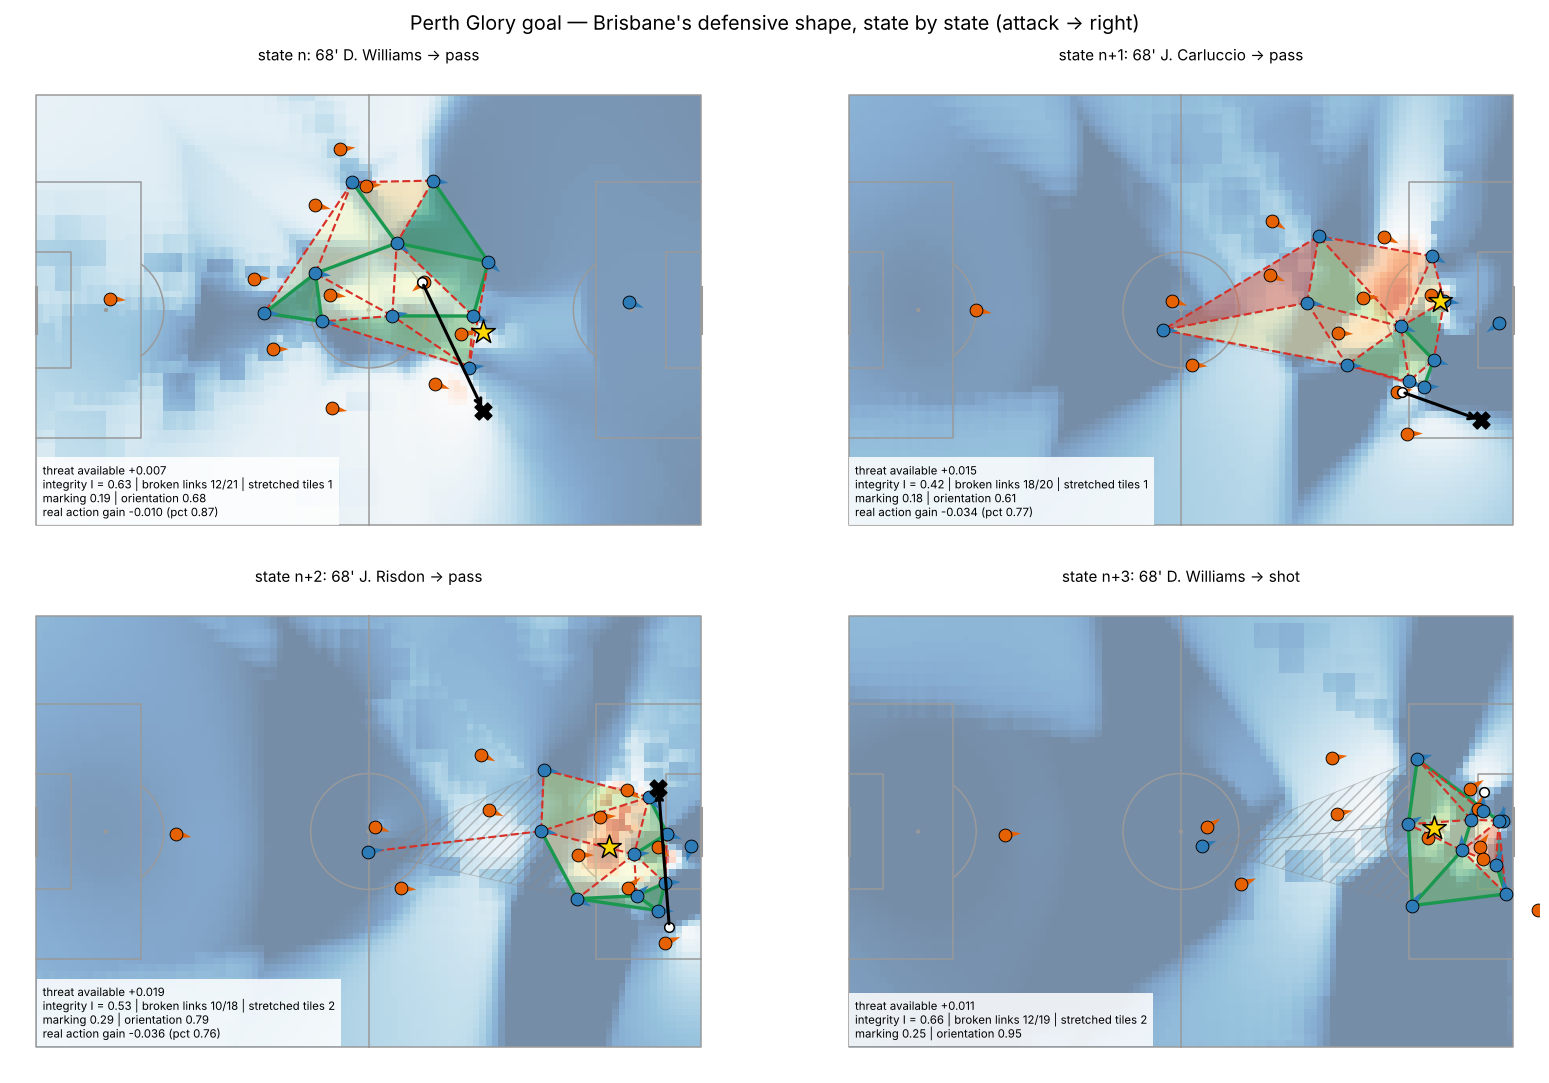

In [9]:
goal_seq_ids = ["8_787", "8_788", "8_789", "8_790"]
goal_idx = [pp.index[pp.event_id == e][0] for e in goal_seq_ids]
goal_states = [evaluate_state(i) for i in goal_idx]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, (out, st, ball, pc, tl), lbl in zip(axes.ravel(), goal_states, ["n", "n+1", "n+2", "n+3"]):
    draw_state(out, st, ball, pc, tl, ax, title=f"state {lbl}: {out['minute']}' {out['player']} → {out['end_type']}")
fig.suptitle("Perth Glory goal — Brisbane's defensive shape, state by state (attack → right)", fontsize=13)
plt.tight_layout(); plt.show()

### The chain, as numbers
* `threat_available` — the most EPV the attack could add with one pass. **Lower = better defending.**
* `action_percentile` — how good the attack's real choice was among all possible passes (1 = they found the best).
* `ΔI` — change in shape integrity caused by the step from $n$ to $n+1$. **Negative = the action broke the shape.**

In [10]:
def chain_table(states):
    df = pd.DataFrame([s[0] for s in states])
    df["ΔI_next"] = df.integrity.shift(-1) - df.integrity
    df["Δthreat_next"] = df.threat_available.shift(-1) - df.threat_available
    cols = ["minute", "player", "end_type", "v_ball", "threat_available", "real_gain", "action_percentile",
            "integrity", "ΔI_next", "links_broken", "n_links", "n_stretched", "marking", "orientation", "Δthreat_next"]
    return df[cols]

goal_chain = chain_table(goal_states)
goal_chain.round(3)

,minute,player,end_type,v_ball,threat_available,real_gain,action_percentile,integrity,ΔI_next,links_broken,n_links,n_stretched,marking,orientation,Δthreat_next
0,68,D. Williams,pass,0.034,0.007,-0.010,0.875,0.628,-0.205,12,21,1,0.194,0.681,0.008
1,68,J. Carluccio,pass,0.057,0.015,-0.034,0.769,0.423,0.105,18,20,1,0.176,0.609,0.004
2,68,J. Risdon,pass,0.054,0.019,-0.036,0.761,0.528,0.134,10,18,2,0.292,0.791,-0.007
3,68,D. Williams,shot,0.064,0.011,NaN,NaN,0.661,NaN,12,19,2,0.246,0.950,NaN


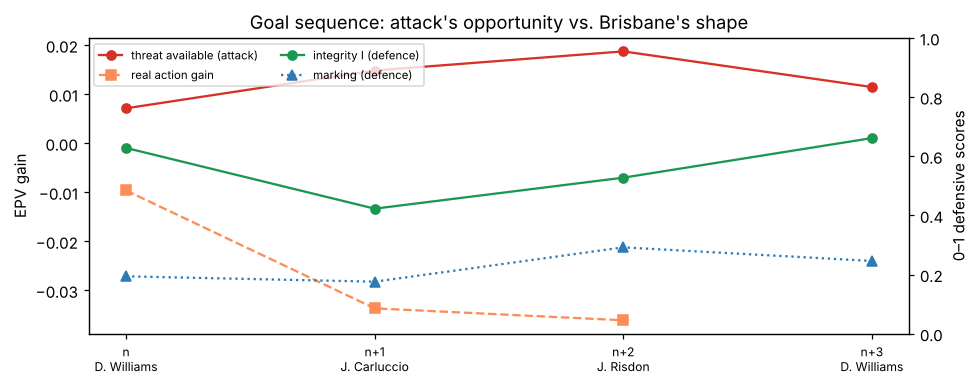

In [11]:
def plot_chain(df, title):
    fig, ax1 = plt.subplots(figsize=(9, 3.6))
    x = np.arange(len(df)); labels = [f"n+{k}\n{p}" if k else f"n\n{p}" for k, p in enumerate(df.player)]
    ax1.plot(x, df.threat_available, "o-", c="#d73027", label="threat available (attack)")
    ax1.plot(x, df.real_gain, "s--", c="#fc8d59", label="real action gain")
    ax1.set_ylabel("EPV gain"); ax1.set_xticks(x); ax1.set_xticklabels(labels, fontsize=8)
    ax2 = ax1.twinx()
    ax2.plot(x, df.integrity, "o-", c="#1a9850", label="integrity I (defence)")
    ax2.plot(x, df.marking, "^:", c="#2c7bb6", label="marking (defence)")
    ax2.set_ylim(0, 1); ax2.set_ylabel("0–1 defensive scores")
    h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, fontsize=7.5, loc="upper left", ncol=2)
    ax1.set_title(title); plt.tight_layout(); plt.show()

plot_chain(goal_chain, "Goal sequence: attack's opportunity vs. Brisbane's shape")

### Who was responsible? Individual quality at state $n+2$ (the cross)

In [12]:
goal_states[2][4]["players"].sort_values("marking")

,player_id,name,x,y,nearest_attacker,dist_m,goal_side,marking,orientation
3,560983,A. Burke-Gilroy,45.76,-12.51,J. Risdon,5.2,True,0.02,0.80
1,69111,H. Bility,46.85,-8.13,N. Blair,5.8,False,0.07,0.52
8,560986,K. Jelacic,32.96,-10.62,N. Pennington,6.9,False,0.07,0.99
4,51002,J. O'Shea,42.35,-10.15,J. Carluccio,1.9,True,0.13,0.55
0,965697,L. Herrington,47.15,-0.37,N. Blair,2.5,True,0.29,0.68
6,795541,Q. MacNicol,27.27,0.06,N. Pennington,6.9,False,0.33,0.94
5,287934,Walid Shour,41.96,-3.62,N. Blair,3.9,False,0.40,0.67
2,51722,J. Hingert,44.29,5.43,K. Ngo,3.6,True,0.45,0.93
9,795537,T. Waddingham,-0.04,-3.20,T. Mrčela,4.1,False,0.50,0.96
7,965698,J. Brazete,27.68,9.73,R. Warland,10.2,True,0.66,0.87


## 8. Case study B — real body orientation (Perth defending)

The body-pose sample covers 77' – 78' of this match: Walid Shour plays J. Brazete, who carries and shoots.
Here the **defending team is Perth**, and we can replace the movement-direction proxy with each defender's
actual torso orientation from the 3-D shoulder joints:

$$\text{facing} = \text{rot}_{90°}\big(\text{rShoulder} - \text{lShoulder}\big)$$

Body pose runs at 25 fps, tracking at 10 fps: tracking frame ≈ pose frame × 0.4.

pose frame 124548 ↔ tracking frame 49819; 18 players with pose; shoulder-normal vs nose agreement (mean cos) = 0.95


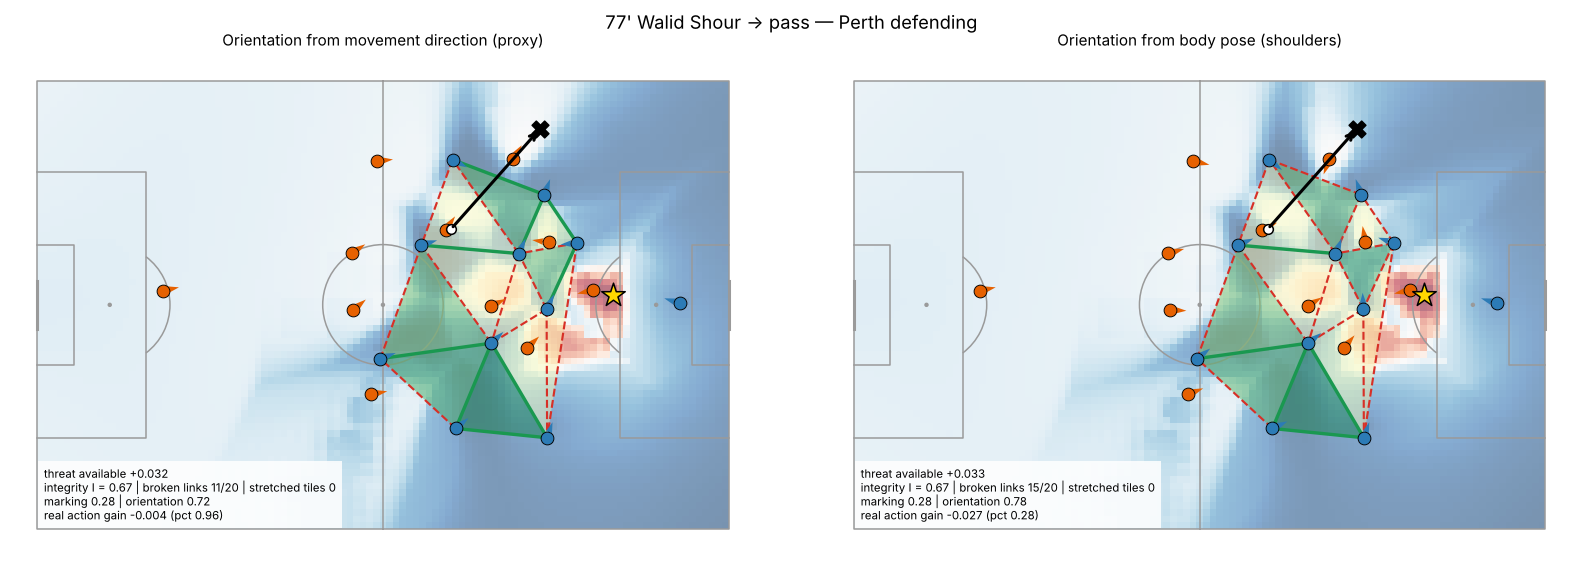

In [13]:
with gzip.open(DATA / "bodypose" / "sample_1925299_phase406.jsonl.gz", "rt") as f:
    pose_rows = [json.loads(l) for l in f]

def pose_facing(row, flip):
    out = {}
    for p in row["player_data"]:
        j = p.get("joints")
        if not j or not j.get("lShoulder") or not j.get("rShoulder"):
            continue
        l = np.array(j["lShoulder"]["xyz"][:2]); r = np.array(j["rShoulder"]["xyz"][:2])
        sh = (r - l) * flip
        out[p["player_id"]] = np.array([-sh[1], sh[0]])         # rotate +90°: shoulder line → chest normal
    return out

shour_i = pp.index[pp.event_id == "8_870"][0]
ev = pp.loc[shour_i]
flip = -1.0 if ev.attacking_side == "right_to_left" else 1.0
pose_frame = int(round(ev.frame_end / 0.4))
row = min(pose_rows, key=lambda r: abs(r["frame"] - pose_frame))
facing_pose = pose_facing(row, flip)

# sanity check: the shoulder-normal should agree with the nose direction
chk = []
for p in row["player_data"]:
    j = p.get("joints")
    if j and j.get("nose") and j.get("neck") and p["player_id"] in facing_pose:
        nose = (np.array(j["nose"]["xyz"][:2]) - np.array(j["neck"]["xyz"][:2])) * flip
        f = facing_pose[p["player_id"]]
        chk.append(np.dot(nose, f) / (np.linalg.norm(nose) * np.linalg.norm(f) + 1e-9))
print(f"pose frame {row['frame']} ↔ tracking frame {ev.frame_end}; {len(facing_pose)} players with pose; "
      f"shoulder-normal vs nose agreement (mean cos) = {np.mean(chk):.2f}")

out_proxy, st_b, ball_b, pc_proxy, tl_proxy = evaluate_state(shour_i)
out_pose, _, _, pc_pose, tl_pose = evaluate_state(shour_i, facing_override=facing_pose)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
draw_state(out_proxy, st_b, ball_b, pc_proxy, tl_proxy, axes[0], title="Orientation from movement direction (proxy)")
draw_state(out_pose, st_b, ball_b, pc_pose, tl_pose, axes[1], title="Orientation from body pose (shoulders)")
fig.suptitle(f"{out_pose['minute']}' {out_pose['player']} → pass — Perth defending", fontsize=12)
plt.tight_layout(); plt.show()

In [14]:
cmp = tl_proxy["players"][["name", "orientation", "marking"]].merge(
    tl_pose["players"][["name", "orientation", "marking"]], on="name", suffixes=("_proxy", "_pose"))
cmp["has_pose"] = cmp.name.map({pid_name[k]: True for k in facing_pose}).fillna(False)
print(f"threat available: proxy {out_proxy['threat_available']:+.4f} → pose {out_pose['threat_available']:+.4f}")
print(f"integrity:        proxy {out_proxy['integrity']:.3f} → pose {out_pose['integrity']:.3f}")
cmp

threat available: proxy +0.0316 → pose +0.0328
integrity:        proxy 0.673 → pose 0.665


,name,orientation_proxy,marking_proxy,orientation_pose,marking_pose,has_pose
0,A. Lebib,0.99,0.85,0.99,0.84,True
1,T. Mrčela,0.61,0.06,0.84,0.08,True
2,J. Risdon,0.18,0.18,0.49,0.25,True
3,R. Warland,0.86,0.10,0.86,0.10,False
4,N. Pennington,0.46,0.26,0.48,0.26,True
5,T. Gomulka,0.70,0.39,0.66,0.40,True
6,J. Carluccio,0.72,0.09,0.81,0.08,True
7,K. Ngo,0.81,0.04,0.70,0.04,True
8,D. Williams,0.99,0.05,1.00,0.06,True
9,N. Blair,0.88,0.78,0.96,0.74,True


### Orientation through the whole body-pose clip
Using every pose frame (25 fps): how square to the ball was each Perth defender as the break developed?

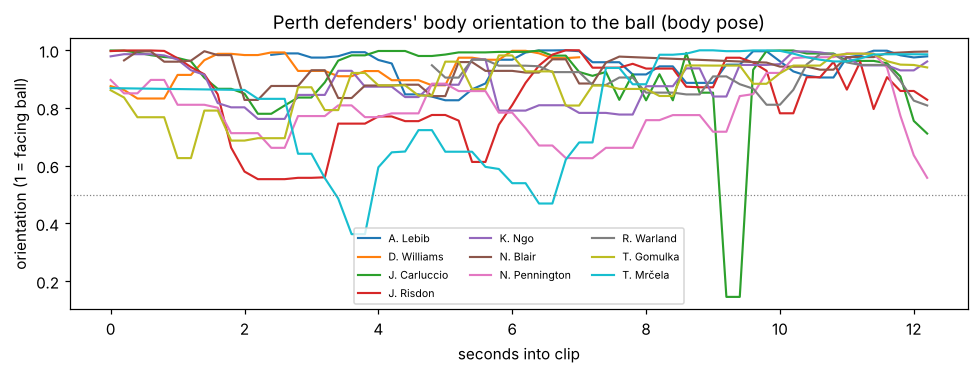

In [15]:
recs = []
for r in pose_rows[::5]:                       # 5 fps is plenty for a plot
    fp = pose_facing(r, flip)
    b = r["ball_data"]
    if b["x"] is None:
        continue
    bxy = np.array([b["x"], b["y"]]) * flip
    for p in r["player_data"]:
        pid = p["player_id"]
        if pid in fp and pid_team.get(pid) != ev.team_id and pid not in goalkeepers:
            pos = np.array([p["x"], p["y"]]) * flip
            tb = bxy - pos; f = fp[pid]
            c = np.dot(tb, f) / (np.linalg.norm(tb) * np.linalg.norm(f) + 1e-9)
            recs.append({"t": (r["frame"] - pose_rows[0]["frame"]) / 25, "name": pid_name.get(pid, pid), "orientation": (1 + c) / 2})
orient = pd.DataFrame(recs)
fig, ax = plt.subplots(figsize=(9, 3.5))
for name, g in orient.groupby("name"):
    ax.plot(g.t, g.orientation.rolling(3, center=True, min_periods=1).median(), label=name, lw=1.4)
ax.axhline(0.5, c="grey", lw=0.8, ls=":")
ax.set_xlabel("seconds into clip"); ax.set_ylabel("orientation (1 = facing ball)")
ax.set_title("Perth defenders' body orientation to the ball (body pose)")
ax.legend(fontsize=7, ncol=3); plt.tight_layout(); plt.show()

## 9. Feasibility check — does the model agree with SkillCorner?

The prototype is only useful if its numbers line up with independent measures. Running it over every
pass in the match (both teams defending) and comparing against:

1. **Pass success** — does the model's $P_{succ}$ at the real target predict whether the pass was completed?
2. **SkillCorner `xpass_completion`** on the targeted passing option.
3. **SkillCorner EPV** — does "threat available" rise with `possession_epv_for_start`?
4. **SkillCorner `xthreat`** of the targeted option — compared with our *value if completed*, $V(target) - V(ball)$.
   (SkillCorner's xthreat assumes the pass arrives; our full gain also subtracts the risk of losing the ball, so
   the risk-free part is the like-for-like comparison.)

In [16]:
from sklearn.metrics import roc_auc_score  # noqa: E402  (pip install scikit-learn if missing)

po = events[events.event_type == "passing_option"]
targeted = po[po.targeted == True].drop_duplicates("associated_player_possession_event_id") \
    .set_index("associated_player_possession_event_id")[["xpass_completion", "xthreat", "received"]]

rows = []
cand = pp[(pp.end_type == "pass")].index
for i in cand:
    ev = pp.loc[i]
    try:
        st, ball = frame_state(int(ev.frame_end), ev.team_id, ev.attacking_side)
        if ball is None or len(st[st.attacking]) < 7 or len(st[~st.attacking]) < 7:
            continue
        pc = pitch_control(st, ball)
    except Exception:
        continue
    # intended target = targeted passing option's location at the pass moment, else the next possession start
    po_i = po[(po.associated_player_possession_event_id == ev.event_id) & (po.targeted == True)]
    if len(po_i):
        tgt = np.array([po_i.iloc[0].x_end, po_i.iloc[0].y_end])
    elif i + 1 < len(pp):
        tgt = np.array([pp.loc[i + 1].x_start, pp.loc[i + 1].y_start])
    else:
        continue
    iy = np.clip(int(round(tgt[1] + HALF_W - 0.5)), 0, len(GRID_Y) - 1)
    ix = np.clip(int(round(tgt[0] + HALF_L - 0.5)), 0, len(GRID_X) - 1)
    rows.append({"event_id": ev.event_id, "team": ev.team_shortname, "defending": team_name[home_id if ev.team_id == away_id else away_id],
                 "p_succ_model": pc["p_succ"][iy, ix], "gain_real": pc["gain"][iy, ix],
                 "reward_if_completed": V[iy, ix] - pc["v_ball"],
                 "threat_available": pc["gain"].max(),
                 "action_percentile": (pc["gain"][pc["p_succ"] > 0.05] < pc["gain"][iy, ix]).mean(),
                 "pass_completed": ev.pass_outcome == "successful",
                 "epv_start": ev.possession_epv_for_start, "pass_epv_delta": ev.pass_epv_delta_for})
val = pd.DataFrame(rows).join(targeted, on="event_id")
print(f"{len(val)} passes evaluated")

auc_model = roc_auc_score(val.pass_completed, val.p_succ_model)
v2 = val.dropna(subset=["xpass_completion"])
auc_sc = roc_auc_score(v2.pass_completed, v2.xpass_completion)
rho_xp = spearmanr(v2.p_succ_model, v2.xpass_completion).statistic
rho_epv = spearmanr(val.threat_available, val.epv_start, nan_policy="omit").statistic
rho_gain = spearmanr(val.gain_real, val.pass_epv_delta, nan_policy="omit").statistic
rho_xt = spearmanr(v2.reward_if_completed, v2.xthreat, nan_policy="omit").statistic
pd.DataFrame({
    "check": ["Pass completion AUC — this model", "Pass completion AUC — SkillCorner xpass_completion",
              "Spearman ρ: model P_succ vs SkillCorner xpass_completion",
              "Spearman ρ: threat available vs SkillCorner EPV at possession start",
              "Spearman ρ: value-if-completed V(target) − V(ball) vs SkillCorner xthreat of the targeted option",
              "Spearman ρ: real-action gain vs SkillCorner pass EPV delta"],
    "value": [auc_model, auc_sc, rho_xp, rho_epv, rho_xt, rho_gain]}).round(3)

912 passes evaluated


,check,value
0,Pass completion AUC — this model,0.813
1,Pass completion AUC — SkillCorner xpass_comple...,0.905
2,Spearman ρ: model P_succ vs SkillCorner xpass_...,0.732
3,Spearman ρ: threat available vs SkillCorner EP...,0.660
4,Spearman ρ: value-if-completed V(target) − V(b...,0.372
5,Spearman ρ: real-action gain vs SkillCorner pa...,0.103


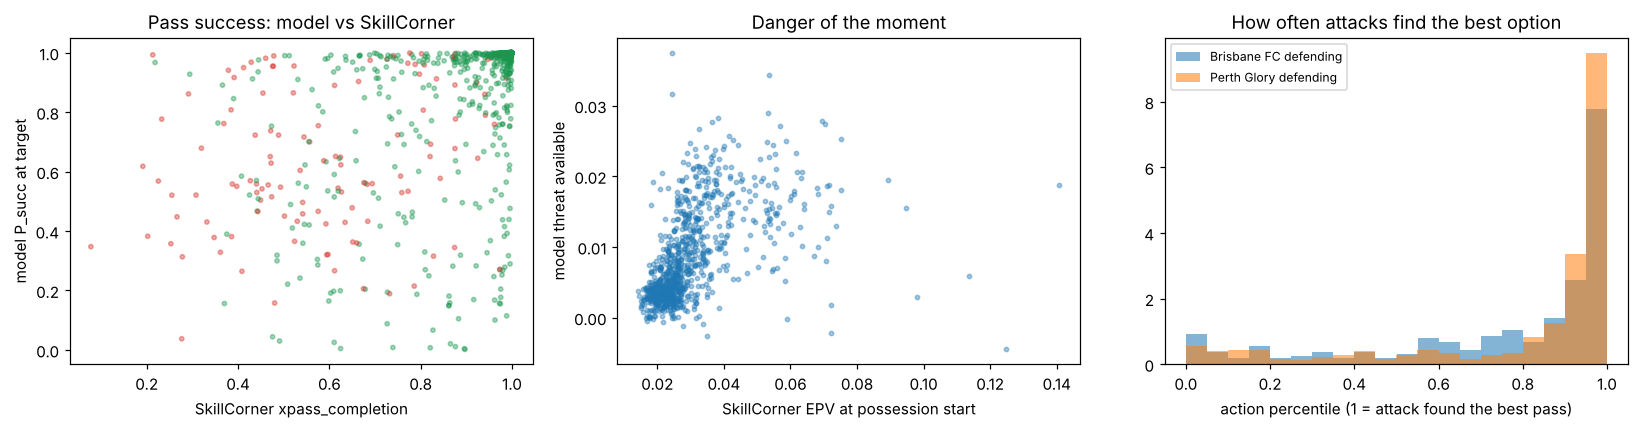

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].scatter(v2.xpass_completion, v2.p_succ_model, s=8, alpha=0.4, c=v2.pass_completed.map({True: "#1a9850", False: "#d73027"}))
axes[0].set_xlabel("SkillCorner xpass_completion"); axes[0].set_ylabel("model P_succ at target"); axes[0].set_title("Pass success: model vs SkillCorner")
axes[1].scatter(val.epv_start, val.threat_available, s=8, alpha=0.4)
axes[1].set_xlabel("SkillCorner EPV at possession start"); axes[1].set_ylabel("model threat available"); axes[1].set_title("Danger of the moment")
for name, g in val.groupby("defending"):
    axes[2].hist(g.action_percentile, bins=20, alpha=0.55, label=f"{name} defending", density=True)
axes[2].set_xlabel("action percentile (1 = attack found the best pass)"); axes[2].set_title("How often attacks find the best option"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [18]:
val.groupby("defending")[["threat_available", "action_percentile", "p_succ_model"]].agg(["mean", "median"]).round(3)

threat_available        action_percentile        p_succ_model  \
                        mean median              mean median         mean   
defending                                                                   
Brisbane FC            0.007  0.004             0.763  0.913        0.804   
Perth Glory            0.010  0.008             0.803  0.946        0.857   

                    
            median  
defending           
Brisbane FC  0.961  
Perth Glory  0.990

## 10. Slide visuals

One figure per slide of the research deck, saved as PNG to `slide_visuals/` next to this notebook.
Every figure reuses objects computed above, so run Sections 1–9 first.

Sizes are in inches at slide scale (the deck is 13.33 × 7.5 in), so fonts read the same on the slide as here:
**side** figures (7.4 × 5.0) sit beside a text column; **wide** figures span the slide.

In [19]:
from matplotlib.patches import FancyBboxPatch, Patch  # noqa: E402
from matplotlib.lines import Line2D  # noqa: E402

SLIDE_DIR = Path.cwd() / "slide_visuals"
SLIDE_DIR.mkdir(exist_ok=True)
SIDE, WIDE = (7.4, 5.0), (12.3, 4.1)
INK, MUTED = "#1f2933", "#6b7280"
C_ATT, C_DEF, C_GOOD, C_BAD, C_SC = "#e66101", "#2c7bb6", "#1a9850", "#d73027", "#7b8794"
plt.rcParams.update({"font.size": 12, "axes.titlesize": 13, "axes.labelsize": 12, "axes.edgecolor": "#c4c9d0",
                     "axes.spines.top": False, "axes.spines.right": False, "text.color": INK,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED})

def save_slide(fig, name):
    path = SLIDE_DIR / f"{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white")
    print("saved", path.name)
    plt.show()

def zoom(ax, st, xmin=-HALF_L, pad=5, extra=()):
    """Crop a pitch axis to the outfield players (and any extra points) beyond x = xmin, keeping the goal line in view."""
    pl = st[~st.gk & (st.x > xmin)]
    xs = np.r_[pl.x, [p[0] for p in extra]]; ys = np.r_[pl.y, [p[1] for p in extra]]
    ax.set_xlim(max(xs.min() - pad, -HALF_L - 1), HALF_L + 1)
    ax.set_ylim(max(ys.min() - pad, -HALF_W - 1), min(ys.max() + pad, HALF_W + 1))

legend_items = [
    Line2D([], [], marker="o", ls="", mfc=C_ATT, mec="k", ms=8, label="attacker"),
    Line2D([], [], marker="o", ls="", mfc=C_DEF, mec="k", ms=8, label="defender"),
    Line2D([], [], color=C_GOOD, lw=2.2, label="intact link"),
    Line2D([], [], color=C_BAD, lw=1.4, ls="--", label="broken link"),
    Line2D([], [], marker="*", ls="", mfc="gold", mec="k", ms=14, label="best option (model)"),
    Line2D([], [], marker="X", ls="", mfc="k", mec="k", ms=10, label="real action"),
]

### Slide 1 — Title: the defensive shape as tiles
Brisbane's shape the moment Carluccio releases the ball before Perth's goal.

saved slide01_title.png


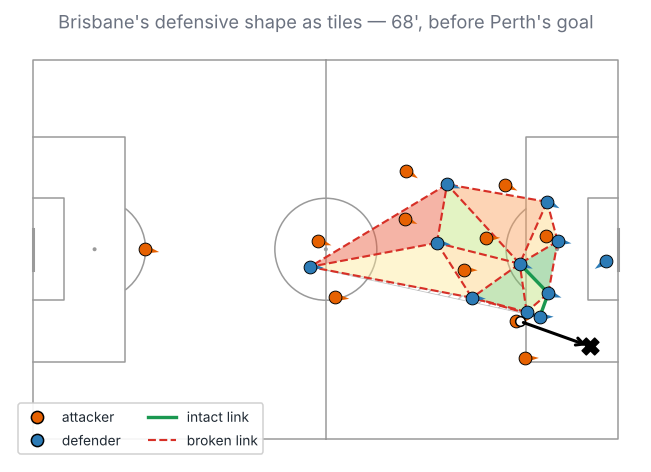

In [20]:
out, st, ball, pc, tl = goal_states[1]
fig, ax = plt.subplots(figsize=SIDE)
draw_state(out, st, ball, pc, tl, ax, layer=None, info=False, show_best=False, title="")
ax.set_title("Brisbane's defensive shape as tiles — 68', before Perth's goal", fontsize=12, color=MUTED)
ax.legend(handles=legend_items[:4], loc="lower left", fontsize=9, framealpha=0.9, ncol=2)
save_slide(fig, "slide01_title")

### Slide 2 — Approach: the four-step pipeline

saved slide02_approach.png


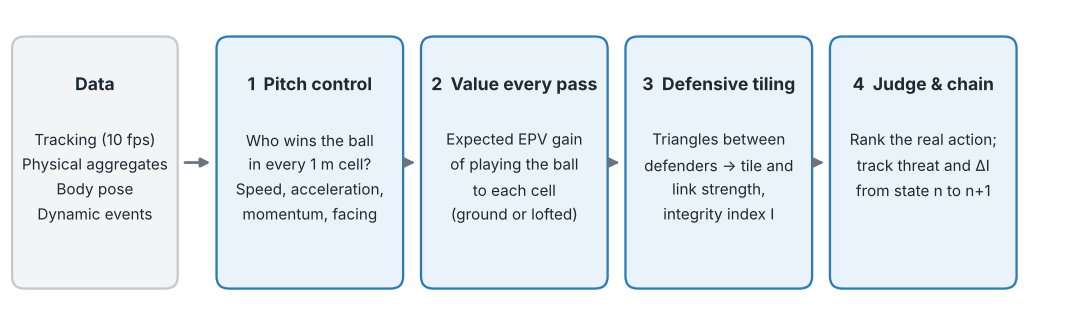

In [21]:
fig, ax = plt.subplots(figsize=(12.3, 3.6)); ax.set_axis_off(); ax.set_xlim(0, 100); ax.set_ylim(0, 30)
def box(x, y, w, h, title, body, fc, ec):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.4,rounding_size=1.2", fc=fc, ec=ec, lw=1.5))
    ax.text(x + w / 2, y + h - 3.2, title, ha="center", va="top", fontsize=11.5, weight="bold", color=INK)
    ax.text(x + w / 2, y + h - 8.6, body, ha="center", va="top", fontsize=10, color=INK, linespacing=1.35)
def arrow(x0, x1, y=15):
    ax.annotate("", xy=(x1, y), xytext=(x0, y), arrowprops=dict(arrowstyle="-|>", lw=1.8, color=MUTED))

box(0.5, 3, 15, 24, "Data", "Tracking (10 fps)\nPhysical aggregates\nBody pose\nDynamic events", "#f3f4f6", "#c4c9d0")
steps = [("1  Pitch control", "Who wins the ball\nin every 1 m cell?\nSpeed, acceleration,\nmomentum, facing"),
         ("2  Value every pass", "Expected EPV gain\nof playing the ball\nto each cell\n(ground or lofted)"),
         ("3  Defensive tiling", "Triangles between\ndefenders → tile and\nlink strength,\nintegrity index I"),
         ("4  Judge & chain", "Rank the real action;\ntrack threat and ΔI\nfrom state n to n+1")]
xs = [20, 39.5, 59, 78.5]
for x, (t, b) in zip(xs, steps):
    box(x, 3, 17, 24, t, b, "#eaf2fb", C_DEF)
arrow(16.3, 19.3)
for a, b in zip(xs[:-1], xs[1:]):
    arrow(a + 17.8, b - 0.7)
save_slide(fig, "slide02_approach")

### Slide 3 — Headline results (912 passes)

saved slide03_results.png


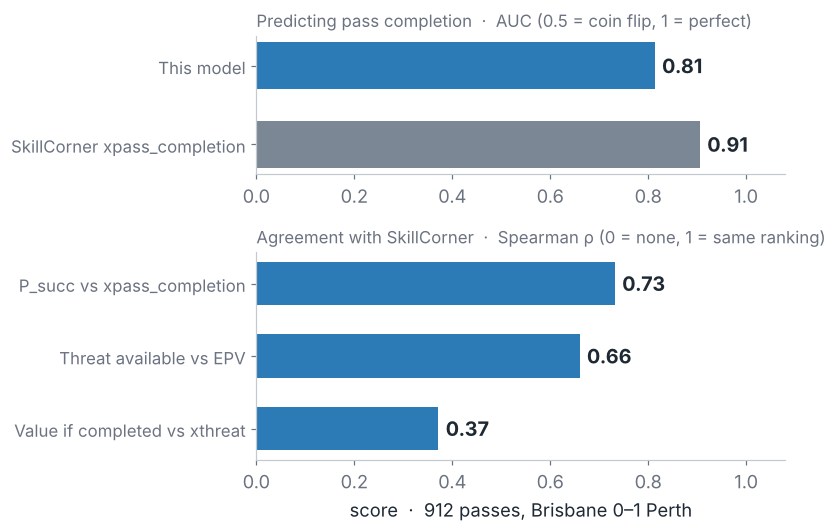

In [22]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=SIDE, gridspec_kw={"height_ratios": [2, 3]})
groups = [(ax1, "Predicting pass completion  ·  AUC (0.5 = coin flip, 1 = perfect)",
           ["This model", "SkillCorner xpass_completion"], [auc_model, auc_sc], [C_DEF, C_SC]),
          (ax2, "Agreement with SkillCorner  ·  Spearman ρ (0 = none, 1 = same ranking)",
           ["P_succ vs xpass_completion", "Threat available vs EPV", "Value if completed vs xthreat"],
           [rho_xp, rho_epv, rho_xt], [C_DEF, C_DEF, C_DEF])]
for ax, ttl, labs, vals, cols in groups:
    y = np.arange(len(vals))[::-1]
    ax.barh(y, vals, color=cols, height=0.6)
    for yi, v in zip(y, vals):
        ax.text(v + 0.015, yi, f"{v:.2f}", va="center", fontsize=13, weight="bold", color=INK)
    ax.set_yticks(y); ax.set_yticklabels(labs, fontsize=11); ax.set_xlim(0, 1.08)
    ax.set_title(ttl, fontsize=11, color=MUTED, loc="left")
ax2.set_xlabel(f"score  ·  {len(val)} passes, Brisbane 0–1 Perth")
plt.tight_layout()
save_slide(fig, "slide03_results")

### Slide 4 — Valuing every pass: $V \times P_{succ} \rightarrow G$
At the moment Risdon crosses (state $n+2$).

saved slide04_epv.png


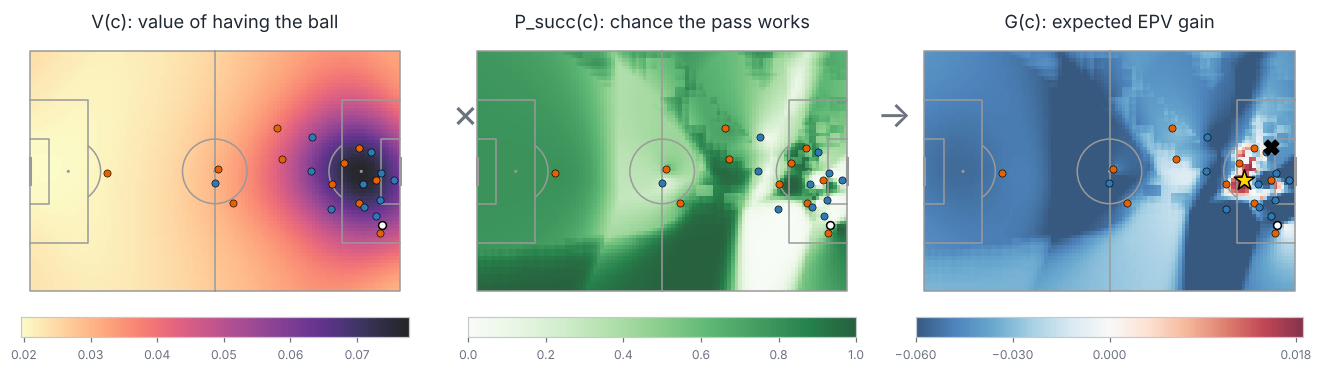

In [23]:
out, st, ball, pc, tl = goal_states[2]
ext = [-HALF_L, HALF_L, -HALF_W, HALF_W]
fig, axes = plt.subplots(1, 3, figsize=WIDE)
panels = [(V, "magma_r", None, "V(c): value of having the ball"),
          (pc["p_succ"], "Greens", (0, 1), "P_succ(c): chance the pass works"),
          (pc["gain"], "RdBu_r", "gain", "G(c): expected EPV gain")]
for ax, (arr, cmap_, lim, ttl) in zip(axes, panels):
    pitch.draw(ax=ax)
    if lim == "gain":
        im = ax.imshow(arr, extent=ext, origin="lower", cmap=cmap_, norm=TwoSlopeNorm(0, vmin=-0.06, vmax=max(arr.max(), 0.01)), alpha=0.8)
    else:
        im = ax.imshow(arr, extent=ext, origin="lower", cmap=cmap_, vmin=None if lim is None else lim[0],
                       vmax=None if lim is None else lim[1], alpha=0.85)
    a = st[st.attacking]; dd = st[~st.attacking]
    ax.scatter(a.x, a.y, s=22, c=C_ATT, edgecolors="k", linewidths=0.4, zorder=5)
    ax.scatter(dd.x, dd.y, s=22, c=C_DEF, edgecolors="k", linewidths=0.4, zorder=5)
    ax.scatter(*ball, s=26, c="white", edgecolors="k", zorder=6)
    ax.set_title(ttl, fontsize=12)
    cb = fig.colorbar(im, ax=ax, orientation="horizontal", fraction=0.05, pad=0.03); cb.ax.tick_params(labelsize=8)
    if lim == "gain":
        cb.set_ticks([-0.06, -0.03, 0, np.floor(arr.max() * 1000) / 1000])   # a tick past vmax breaks a TwoSlopeNorm colorbar
axes[2].scatter(*out["best_xy"], marker="*", s=200, c="gold", edgecolors="k", zorder=7)
axes[2].scatter(*out["real_xy"], marker="X", s=90, c="k", zorder=7)
fig.text(0.355, 0.56, "×", fontsize=26, ha="center", color=MUTED)
fig.text(0.672, 0.56, "→", fontsize=24, ha="center", color=MUTED)
plt.tight_layout()
save_slide(fig, "slide04_epv")

### Slide 5 — Pitch control: the race, then the pass
Same moment. Left: who wins the race to each cell. Right: after adding interception on the ground and the lofted option.

saved slide05_pitch_control.png


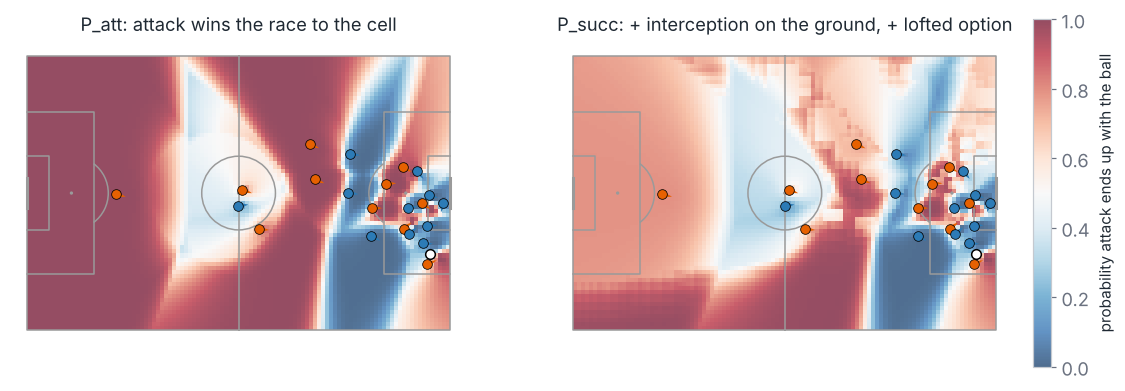

In [24]:
fig, axes = plt.subplots(1, 2, figsize=WIDE)
for ax, arr, ttl in zip(axes, [pc["p_att"], pc["p_succ"]],
                        ["P_att: attack wins the race to the cell", "P_succ: + interception on the ground, + lofted option"]):
    pitch.draw(ax=ax)
    im = ax.imshow(arr, extent=ext, origin="lower", cmap="RdBu_r", vmin=0, vmax=1, alpha=0.7)
    a = st[st.attacking]; dd = st[~st.attacking]
    fa = pc["facing"]
    for msk, col in (((st.attacking).to_numpy(), C_ATT), ((~st.attacking).to_numpy(), C_DEF)):
        s_ = st[msk]; f = fa[msk]; f = f / (np.linalg.norm(f, axis=1, keepdims=True) + 1e-9) * 2.5
        ax.scatter(s_.x, s_.y, s=40, c=col, edgecolors="k", linewidths=0.5, zorder=5)
        ax.quiver(s_.x, s_.y, f[:, 0], f[:, 1], color=col, angles="xy", scale_units="xy", scale=1, width=0.004, zorder=4)
    ax.scatter(*ball, s=40, c="white", edgecolors="k", zorder=6)
    ax.set_title(ttl, fontsize=12)
cb = fig.colorbar(im, ax=axes, orientation="vertical", fraction=0.025, pad=0.02)
cb.set_label("probability attack ends up with the ball", fontsize=10)
save_slide(fig, "slide05_pitch_control")

### Slide 6 — Defensive tiling, annotated
State $n$ (Williams's pass): a mix of strong and weak tiles.

saved slide06_tiling.png


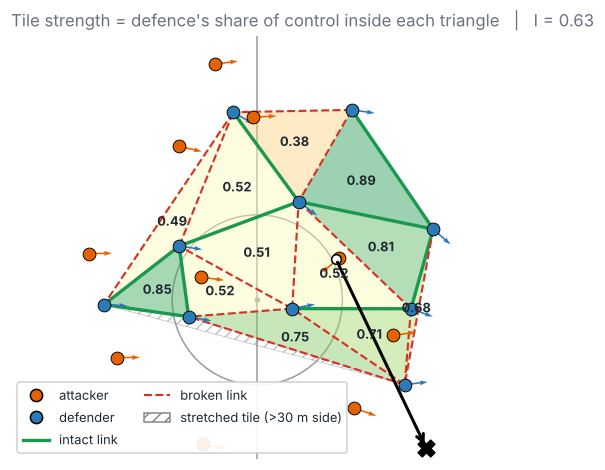

In [25]:
out, st, ball, pc, tl = goal_states[0]
fig, ax = plt.subplots(figsize=SIDE)
draw_state(out, st, ball, pc, tl, ax, layer=None, info=False, show_best=False, title="")
for t in tl["tiles"].itertuples():
    if not t.stretched and not np.isnan(t.strength):
        cx, cy = t.verts.mean(0)
        ax.text(cx, cy, f"{t.strength:.2f}", fontsize=8.5, ha="center", va="center", color=INK, weight="bold", zorder=9)
d = st[~st.attacking & ~st.gk]
ax.set_xlim(d.x.min() - 10, d.x.max() + 12); ax.set_ylim(d.y.min() - 8, d.y.max() + 8)
ax.set_title(f"Tile strength = defence's share of control inside each triangle   |   I = {out['integrity']:.2f}",
             fontsize=11, color=MUTED, loc="left")
ax.legend(handles=legend_items[:4] + [Patch(fc="none", ec="#888888", hatch="///", label="stretched tile (>30 m side)")],
          loc="lower left", fontsize=8.5, framealpha=0.92, ncol=2)
save_slide(fig, "slide06_tiling")

### Slide 7 — Judging the real action
Left: Risdon's cross against the model's best option. Right: the action-percentile problem across all passes.

saved slide07_judging.png


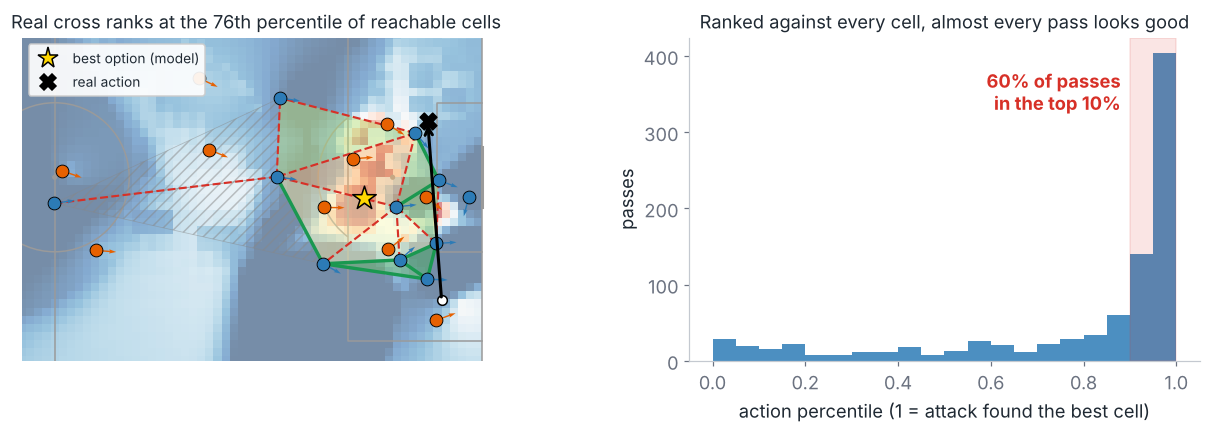

In [26]:
out, st, ball, pc, tl = goal_states[2]
fig, axes = plt.subplots(1, 2, figsize=WIDE, gridspec_kw={"width_ratios": [1.45, 1]})
draw_state(out, st, ball, pc, tl, axes[0], layer="gain", info=False,
           title=f"Real cross ranks at the {out['action_percentile']*100:.0f}th percentile of reachable cells", title_size=12)
zoom(axes[0], st, xmin=0, extra=[out["best_xy"], out["real_xy"]])
axes[0].legend(handles=legend_items[4:], loc="upper left", fontsize=9, framealpha=0.92)
ax = axes[1]
ax.hist(val.action_percentile, bins=20, range=(0, 1), color=C_DEF, alpha=0.85)
share_top = (val.action_percentile > 0.9).mean()
ax.axvspan(0.9, 1.0, color=C_BAD, alpha=0.12)
ax.text(0.88, ax.get_ylim()[1] * 0.9, f"{share_top:.0%} of passes\nin the top 10%", ha="right", va="top", fontsize=12, color=C_BAD, weight="bold")
ax.set_xlabel("action percentile (1 = attack found the best cell)"); ax.set_ylabel("passes")
ax.set_title("Ranked against every cell, almost every pass looks good", fontsize=12)
plt.tight_layout()
save_slide(fig, "slide07_judging")

### Slide 8 — Case study: Perth's goal, state by state

saved slide08_goal_case.png


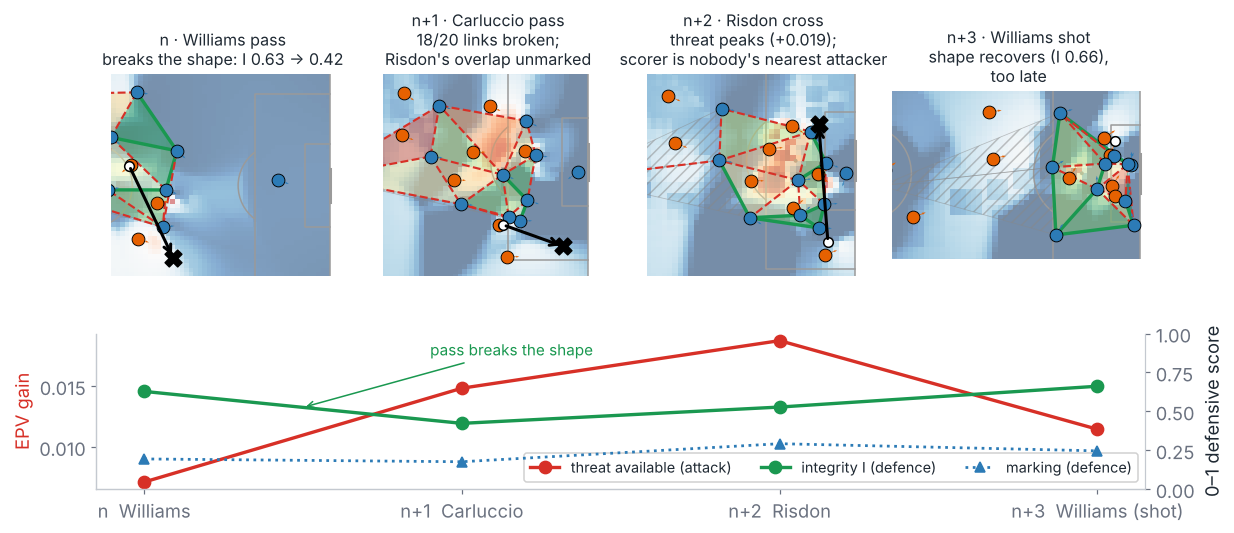

In [27]:
fig = plt.figure(figsize=(12.3, 4.9))
gs = fig.add_gridspec(2, 4, height_ratios=[1.3, 1], hspace=0.32, wspace=0.05)
captions = [f"n · Williams pass\nbreaks the shape: I {goal_chain.integrity[0]:.2f} → {goal_chain.integrity[1]:.2f}",
            f"n+1 · Carluccio pass\n{goal_chain.links_broken[1]}/{goal_chain.n_links[1]} links broken;\nRisdon's overlap unmarked",
            f"n+2 · Risdon cross\nthreat peaks ({goal_chain.threat_available[2]:+.3f});\nscorer is nobody's nearest attacker",
            f"n+3 · Williams shot\nshape recovers (I {goal_chain.integrity[3]:.2f}),\ntoo late"]
for k in range(4):
    ax = fig.add_subplot(gs[0, k])
    o, s_, b, p_, t_ = goal_states[k]
    draw_state(o, s_, b, p_, t_, ax, layer="gain", info=False, show_best=False, title=captions[k], title_size=10.5)
    zoom(ax, s_, xmin=8, pad=4, extra=[b] + ([o["real_xy"]] if o.get("real_xy") else []))
ax = fig.add_subplot(gs[1, :])
x = np.arange(4)
ax.plot(x, goal_chain.threat_available, "o-", c=C_BAD, lw=2.2, ms=8, label="threat available (attack)")
ax.set_ylabel("EPV gain", color=C_BAD); ax.set_xticks(x)
ax.set_xticklabels(["n  Williams", "n+1  Carluccio", "n+2  Risdon", "n+3  Williams (shot)"])
ax2 = ax.twinx(); ax2.spines["right"].set_visible(True)
ax2.plot(x, goal_chain.integrity, "o-", c=C_GOOD, lw=2.2, ms=8, label="integrity I (defence)")
ax2.plot(x, goal_chain.marking, "^:", c=C_DEF, lw=1.8, ms=7, label="marking (defence)")
ax2.set_ylim(0, 1); ax2.set_ylabel("0–1 defensive score")
ax2.annotate("pass breaks the shape", xy=(0.5, (goal_chain.integrity[0] + goal_chain.integrity[1]) / 2), xytext=(0.9, 0.86),
             fontsize=10, color=C_GOOD, arrowprops=dict(arrowstyle="->", color=C_GOOD))
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="lower right", fontsize=9.5, ncol=3, framealpha=0.9)
save_slide(fig, "slide08_goal_case")

### Slide 9 — Body orientation changes the verdict

saved slide09_body_pose.png


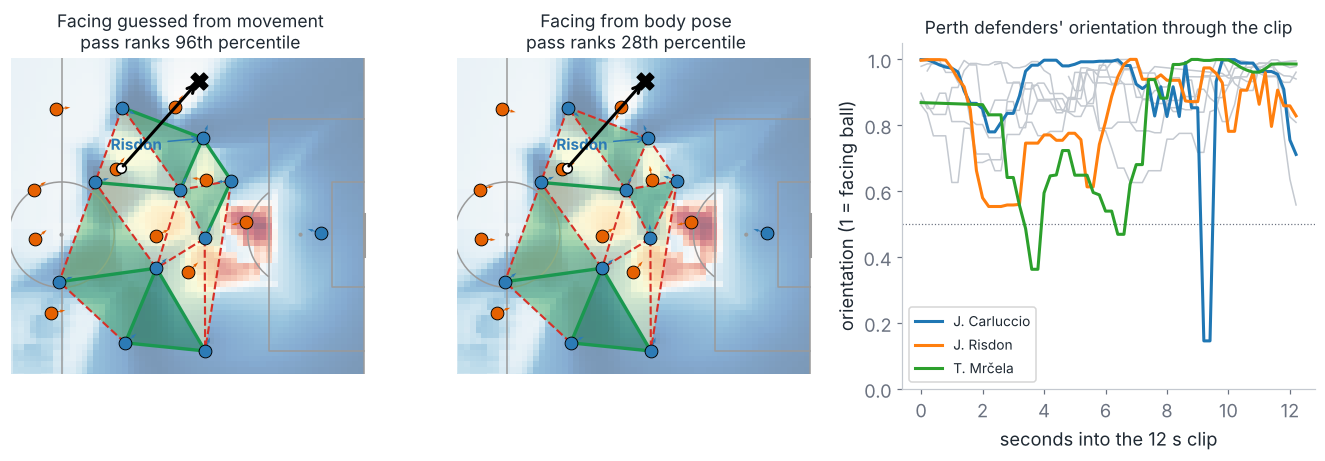

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(12.3, 4.3), gridspec_kw={"width_ratios": [1, 1, 1.15]})
for ax, (o, p_, t_), ttl in zip(axes[:2], [(out_proxy, pc_proxy, tl_proxy), (out_pose, pc_pose, tl_pose)],
                                 ["Facing guessed from movement", "Facing from body pose"]):
    draw_state(o, st_b, ball_b, p_, t_, ax, layer="gain", info=False, title="", show_best=False)
    ax.set_title(f"{ttl}\npass ranks {o['action_percentile']*100:.0f}th percentile", fontsize=11.5)
    r = st_b[st_b.name == "J. Risdon"].iloc[0]
    ax.annotate("Risdon", xy=(r.x, r.y), xytext=(r.x - 16, r.y - 2), fontsize=10, weight="bold", color=C_DEF,
                arrowprops=dict(arrowstyle="->", color=C_DEF))
    zoom(ax, st_b, xmin=-12, pad=4, extra=[o["real_xy"]])
ax = axes[2]
for name, g in orient.groupby("name"):
    sm = g.orientation.rolling(3, center=True, min_periods=1).median()
    hl = name in ("J. Risdon", "J. Carluccio", "T. Mrčela")
    ax.plot(g.t, sm, lw=2 if hl else 1, color=None if hl else "#c4c9d0", label=name if hl else None, zorder=3 if hl else 1)
ax.axhline(0.5, c=MUTED, lw=0.8, ls=":")
ax.set_ylim(0, 1.05); ax.set_xlabel("seconds into the 12 s clip"); ax.set_ylabel("orientation (1 = facing ball)")
ax.set_title("Perth defenders' orientation through the clip", fontsize=11.5)
ax.legend(fontsize=9, loc="lower left")
plt.tight_layout()
save_slide(fig, "slide09_body_pose")

### Slide 10 — Overall evaluation: calibration of pass success
Bin passes by predicted completion and compare with the share actually completed. A perfectly calibrated model sits on the diagonal.

saved slide10_evaluation.png


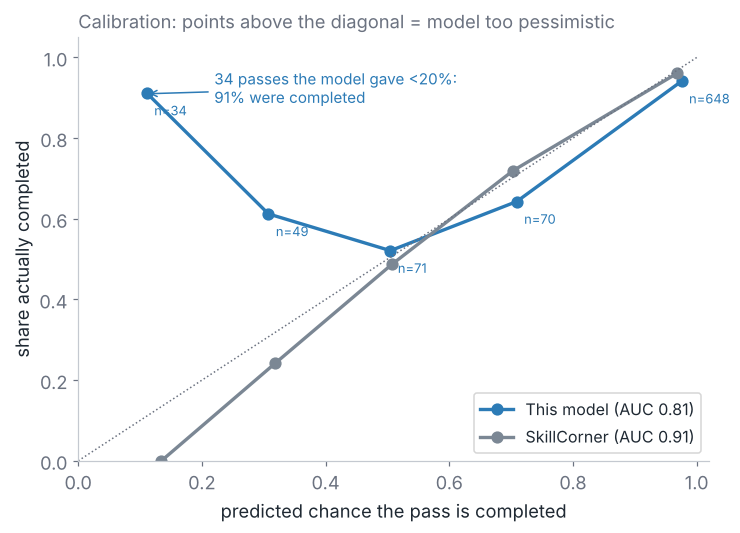

In [29]:
def calib(pred, actual, bins=np.linspace(0, 1, 6)):
    idx = np.clip(np.digitize(pred, bins) - 1, 0, len(bins) - 2)
    df_ = pd.DataFrame({"b": idx, "p": pred, "a": actual}).groupby("b").agg(p=("p", "mean"), a=("a", "mean"), n=("a", "size"))
    return df_

fig, ax = plt.subplots(figsize=SIDE)
for pred, lab, col in [(v2.p_succ_model, f"This model (AUC {auc_model:.2f})", C_DEF),
                       (v2.xpass_completion, f"SkillCorner (AUC {auc_sc:.2f})", C_SC)]:
    cdf = calib(pred.to_numpy(), v2.pass_completed.to_numpy().astype(float))
    ax.plot(cdf.p, cdf.a, "o-", c=col, lw=2.2, ms=7, label=lab)
    if col == C_SC:
        continue
    for _, r in cdf.iterrows():
        off = -0.055
        ax.text(r.p + 0.012, r.a + off, f"n={int(r.n)}", fontsize=8.5, color=col, ha="left")
ax.plot([0, 1], [0, 1], ls=":", c=MUTED, lw=1)
ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.05)
ax.set_xlabel("predicted chance the pass is completed"); ax.set_ylabel("share actually completed")
low = v2.p_succ_model < 0.2
ax.annotate(f"{low.sum()} passes the model gave <20%:\n{v2.pass_completed[low].mean():.0%} were completed",
            xy=(0.11, 0.91), xytext=(0.22, 0.97), fontsize=10, color=C_DEF, va="top",
            arrowprops=dict(arrowstyle="->", color=C_DEF))
ax.set_title("Calibration: points above the diagonal = model too pessimistic", fontsize=12, color=MUTED, loc="left")
ax.legend(loc="lower right", fontsize=10.5)
save_slide(fig, "slide10_evaluation")

### Slide 11 — Next steps: impact vs effort

saved slide11_next_steps.png


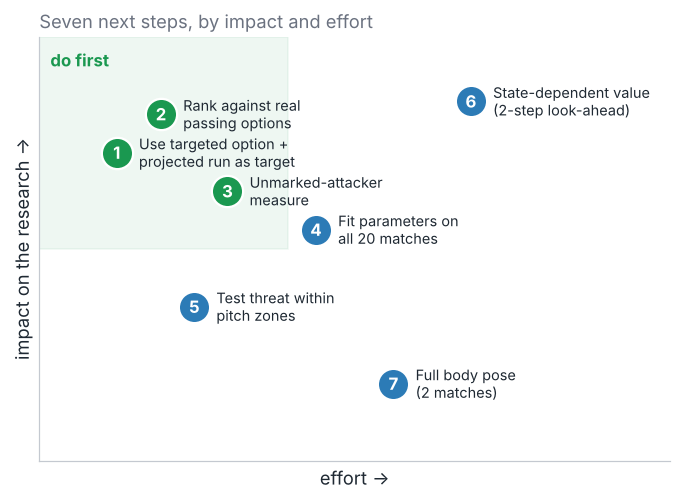

In [30]:
steps_ = [("Use targeted option +\nprojected run as target", 1.2, 4.2),
          ("Rank against real\npassing options", 1.6, 4.5),
          ("Unmarked-attacker\nmeasure", 2.2, 3.9),
          ("Fit parameters on\nall 20 matches", 3.0, 3.6),
          ("Test threat within\npitch zones", 1.9, 3.0),
          ("State-dependent value\n(2-step look-ahead)", 4.4, 4.6),
          ("Full body pose\n(2 matches)", 3.7, 2.4)]
fig, ax = plt.subplots(figsize=SIDE)
ax.axvspan(0, 2.75, ymin=0.5, color=C_GOOD, alpha=0.07)
for i, (t, e, imp) in enumerate(steps_, 1):
    ax.scatter(e, imp, s=420, c=C_GOOD if i <= 3 else C_DEF, edgecolors="white", linewidths=1.5, zorder=3)
    ax.text(e, imp, str(i), color="white", ha="center", va="center", fontsize=11, weight="bold", zorder=4)
    ax.text(e + 0.2, imp, t, fontsize=9.5, va="center", color=INK)
ax.set_xlim(0.5, 6.2); ax.set_ylim(1.8, 5.1)
ax.set_xlabel("effort →"); ax.set_ylabel("impact on the research →")
ax.set_xticks([]); ax.set_yticks([])
ax.text(0.6, 5.0, "do first", fontsize=11, color=C_GOOD, weight="bold", va="top")
ax.set_title("Seven next steps, by impact and effort", fontsize=12, color=MUTED, loc="left")
save_slide(fig, "slide11_next_steps")

## 11. What this tells us, and what to build next

**Feasible, with caveats.** The pieces you need all exist in this data: tracking for positions/velocities,
physical aggregates for per-player speed and acceleration, body pose for orientation, and SkillCorner's own
EPV / pass-completion values as ground truth to calibrate against. Read the validation table above for how
far the uncalibrated prototype already agrees.

**Known simplifications in this prototype**
1. **Value surface** is location-only (no pressure, no defensive context). Swapping in a full EPV model — or
   regressing $V$ on the pitch-control features — is the biggest single improvement.
2. **Ground passes only.** Lofted balls/crosses ignore interception, so threat in wide crossing positions
   is underestimated (see the goal sequence).
3. **Passes only.** Carries and shots are not yet in the action set. Adding *carry* options (cells the ball
   carrier reaches before any defender) and *shot* value (xG) completes "all possible plays".
4. **Parameters are not fitted.** Reaction time, ball speed, $\sigma$ and turn rate should be fitted by
   maximising the pass-completion likelihood across all 20 matches.
5. **Body pose** is only in a 12-second sample here. The full files (2 matches) are on Hugging Face — enough
   to learn how much orientation actually changes arrival times, and to calibrate the movement-direction proxy
   for the 18 matches without pose.
6. **Actions are judged at the release frame.** The real target is where the ball was *received*, but at the
   moment of the pass the receiver is often still running onto it — so the model sees that cell as contested and
   real-action gains come out negative (see the goal chain). Evaluating each target at the receiver's projected
   run (the `off_ball_run` events give the run's end point) would fix this.
7. **One-step look-ahead only.** The chain is evaluated on real successive states. A true "chain reaction"
   value would roll each candidate action forward (e.g. a 2-step search over top options, or a learned
   value of the post-action state) — this is where your tiling-as-DP idea fits: tiles as states, links as
   transitions, and the value of breaking a tile computed recursively.

**Suggested next steps**
* Fit the model parameters on all 20 matches; report AUC against SkillCorner `xpass_completion`.
* Aggregate per team and per defender: average threat conceded per state, ΔI per action, links broken per
  phase type (`team_out_of_possession_phase_type`: low block, mid block, high press…).
* Attribute every broken link to the two defenders who own it — this gives an individual "shape
  responsibility" metric that combines marking, orientation and physical reach.